In [1]:
from collections import defaultdict

import torch
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)

In [3]:
x = torch.linspace(-2, 2, 100).reshape(-1, 1)
y = 3 * x + 2 + 0.2 * torch.randn_like(x)

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: torch.Size([100, 1])
y shape: torch.Size([100, 1])


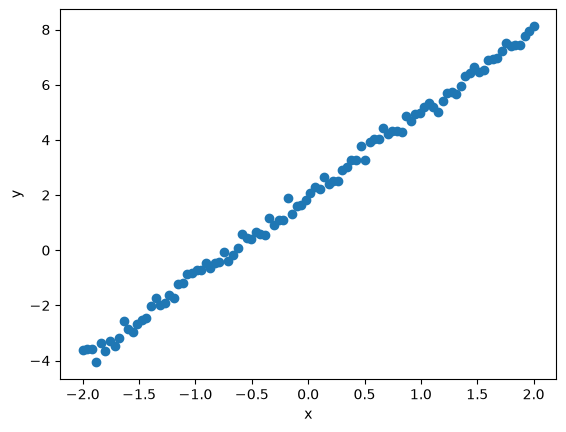

In [4]:
plt.scatter(x.numpy(), y.numpy())
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [5]:
w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

y_pred = w * x + b

print("w:", w.item())
print("b:", b.item())

print("Predictions shape:", y_pred.shape)
print("First five predictions:\n", y_pred[:5])

w: -0.5671805739402771
b: -0.5706474184989929
Predictions shape: torch.Size([100, 1])
First five predictions:
 tensor([[0.5637],
        [0.5408],
        [0.5179],
        [0.4950],
        [0.4720]], grad_fn=<SliceBackward0>)


In [6]:
loss = torch.mean((y_pred - y) ** 2)
print("Initial loss:", loss.item())

Initial loss: 23.988872528076172


In [7]:
loss.shape

torch.Size([])

In [8]:
# calgulate gradients
loss.backward()

print("w:", w.item())
print("b:", b.item())

print("Gradient of w:", w.grad.item())
print("Gradient of b:", b.grad.item())

w: -0.5671805739402771
b: -0.5706474184989929
Gradient of w: -9.696634292602539
Gradient of b: -5.165201187133789


In [9]:
learning_rate = 0.05
steps = 300

for step in range(steps):
    w.grad = None
    b.grad = None

    y_pred = w * x + b
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    if step % 30 == 0:
        print(f"Step: {step}, loss: {loss.item():4f}")

Step: 0, loss: 23.988873
Step: 30, loss: 0.053178
Step: 60, loss: 0.038538
Step: 90, loss: 0.038516
Step: 120, loss: 0.038516
Step: 150, loss: 0.038516
Step: 180, loss: 0.038516
Step: 210, loss: 0.038516
Step: 240, loss: 0.038516
Step: 270, loss: 0.038516


In [10]:
print(w.item(), b.item(), loss.item())

2.99705171585083 2.0119519233703613 0.03851611912250519


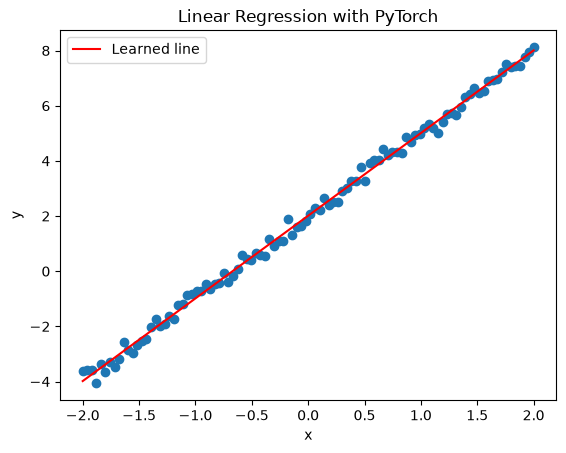

Learned weight: 2.9971
Learned bias: 2.0120
Final MSE: 0.0385


In [11]:
with torch.no_grad():
    y_pred = w * x + b

plt.scatter(x.numpy(), y.numpy())
plt.plot(x.numpy(), y_pred.numpy(), color="red", label="Learned line")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression with PyTorch")
plt.legend()
plt.show()

print(f"Learned weight: {w.item():.4f}")
print(f"Learned bias: {b.item():.4f}")
print(f"Final MSE: {loss.item():.4f}")

## Exercise

Diagnostic 02 — Learn a line with a twist
Predict a system's output
PyTorch · Beginner → Intermediate
Your task is to train a model to discover a hidden linear relationship from noisy data. This time, you'll generate the data yourself, choose your initialization, train the model, and evaluate it.











The scenario
Imagine a sensor measures the output of a system. Its readings approximately follow:
\[
y=-2.5x+4+\text{noise}
\]

Your model doesn't know the true weight or bias. It must learn them from the data.
Your tasks
Challenge checklist
0 of 5



[ ] 1. Generate the dataset
Create 150 values of x evenly spaced from -3 to 3, shaped (150, 1). Generate y using the hidden relationship above, adding random noise with standard deviation 0.3. Use torch.manual_seed(21).


[ ] 2. Initialize the model
Create learnable scalar parameters w and b. This time, initialize both to zero rather than random values.


[ ] 3. Train manually
Use mean squared error and manual gradient descent, as in Diagnostic 01. Choose a learning rate and number of steps that let the loss converge. Clear gradients and update parameters correctly.


[ ] 4. Evaluate the model
Print the final w, b, and MSE. Check whether the learned parameters are close to -2.5 and 4.


[ ] 5. Visualize
Plot the noisy data and your learned line on the same graph.



The extra challenge
In Diagnostic 01, you watched the loss decrease every 30 steps. This time, experiment with the learning rate.
Train the model with two different learning rates. For example, try 0.01 and 0.1, using the same initial parameters and dataset for a fair comparison.
Record:
- How quickly does each run reduce the loss?
- Does either run fail to converge or become unstable?
- Do both runs eventually learn approximately the same weight and bias?
You don't need to plot loss curves yet; comparing the printed losses is enough.
Rules for this exercise
- You can reuse the ideas from Diagnostic 01, but write the code yourself.
- Don't use torch.nn.Linear, an optimizer, or loss.backward() alternatives yet. The purpose is to reinforce your understanding of manual gradient descent.
- Don't worry if you need to look up syntax. Focus on understanding each operation.
- If something goes wrong, debug it before starting over.

In [12]:
torch.manual_seed(21)

x = torch.linspace(-3, 3, 150).reshape(-1, 1)
y = -2.5 * x + 4 + torch.randn_like(x) * 0.3

Text(0, 0.5, 'y')

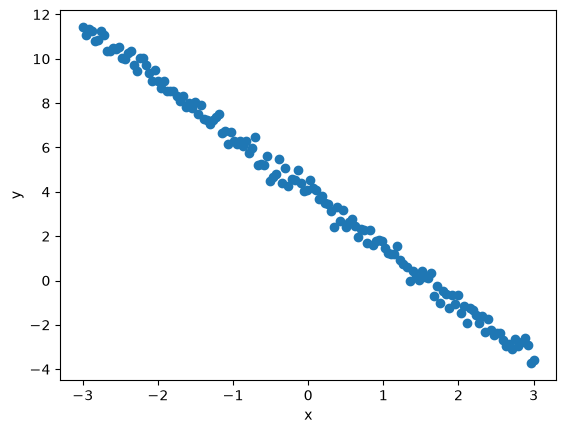

In [13]:
plt.scatter(x, y)
plt.xlabel("x")
plt.ylabel("y")

In [14]:
w = torch.scalar_tensor(0.0, requires_grad=True)
b = torch.scalar_tensor(0.0, requires_grad=True)

learning_rate = 0.01
steps = 500

losses = defaultdict(list)
for step in range(steps):
    w.grad = None
    b.grad = None

    y_pred = w * x + b
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    losses["step"].append(step)
    losses["loss"].append(loss.item())
    if step % 20 == 0:
        print(f"Step: {step}, Loss: {loss}")

Step: 0, Loss: 35.21710205078125
Step: 20, Loss: 8.745226860046387
Step: 40, Loss: 3.375885009765625
Step: 60, Loss: 1.5056198835372925
Step: 80, Loss: 0.7145638465881348
Step: 100, Loss: 0.3654470443725586
Step: 120, Loss: 0.2101270705461502
Step: 140, Loss: 0.14092382788658142
Step: 160, Loss: 0.11008160561323166
Step: 180, Loss: 0.09633541107177734
Step: 200, Loss: 0.09020864963531494
Step: 220, Loss: 0.08747801184654236
Step: 240, Loss: 0.08626095950603485
Step: 260, Loss: 0.0857185572385788
Step: 280, Loss: 0.08547678589820862
Step: 300, Loss: 0.08536901324987411
Step: 320, Loss: 0.08532100915908813
Step: 340, Loss: 0.08529958873987198
Step: 360, Loss: 0.08529004454612732
Step: 380, Loss: 0.08528581261634827
Step: 400, Loss: 0.08528390526771545
Step: 420, Loss: 0.085283063352108
Step: 440, Loss: 0.08528269082307816
Step: 460, Loss: 0.08528252691030502
Step: 480, Loss: 0.08528245985507965


In [15]:
print(w.item(), b.item(), loss.item())

-2.5134260654449463 3.990509271621704 0.08528241515159607


### Did training fail? Why don't we have a zero loss?
Training has not failed. The data contains random noise, so the observed targets do not lie perfectly on the underlying linear relationship. The model has learned parameters close to the true values, but it cannot predict the random noise added to each observation. Therefore, a nonzero MSE is expected.

Text(0, 0.5, 'losses')

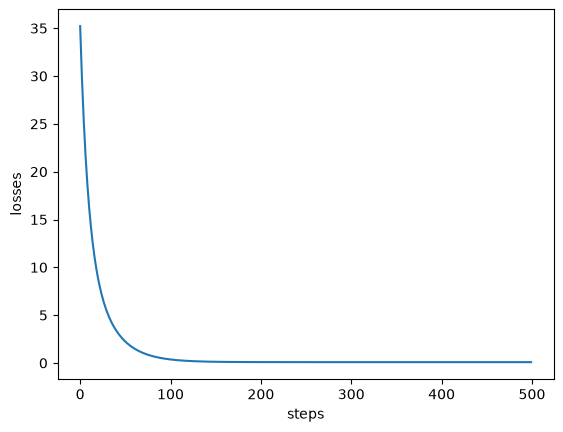

In [16]:
plt.plot(losses["step"], losses["loss"])
plt.xlabel("steps")
plt.ylabel("losses")

In [17]:
w = torch.scalar_tensor(0.0, requires_grad=True)
b = torch.scalar_tensor(0.0, requires_grad=True)

learning_rate = 0.1
steps = 60

losses = defaultdict(list)
for step in range(steps):
    w.grad = None
    b.grad = None

    y_pred = w * x + b
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    losses["step"].append(step)
    losses["loss"].append(loss.item())
    if step % 2 == 0:
        print(f"Step: {step}, Loss: {loss}")

Step: 0, Loss: 35.21710205078125
Step: 2, Loss: 7.061618804931641
Step: 4, Loss: 2.7678298950195312
Step: 6, Loss: 1.1799246072769165
Step: 8, Loss: 0.5335503816604614
Step: 10, Loss: 0.2688906192779541
Step: 12, Loss: 0.16048826277256012
Step: 14, Loss: 0.1160866916179657
Step: 16, Loss: 0.09789981693029404
Step: 18, Loss: 0.0904504805803299
Step: 20, Loss: 0.08739924430847168
Step: 22, Loss: 0.08614945411682129
Step: 24, Loss: 0.08563754707574844
Step: 26, Loss: 0.08542787283658981
Step: 28, Loss: 0.08534196019172668
Step: 30, Loss: 0.0853068009018898
Step: 32, Loss: 0.08529239147901535
Step: 34, Loss: 0.0852864682674408
Step: 36, Loss: 0.08528406172990799
Step: 38, Loss: 0.08528308570384979
Step: 40, Loss: 0.08528266847133636
Step: 42, Loss: 0.08528250455856323
Step: 44, Loss: 0.08528243005275726
Step: 46, Loss: 0.08528239279985428
Step: 48, Loss: 0.08528239279985428
Step: 50, Loss: 0.08528239279985428
Step: 52, Loss: 0.08528239279985428
Step: 54, Loss: 0.08528238534927368
Step: 56,

In [18]:
print(w.item(), b.item(), loss.item())

-2.513427734375 3.9906668663024902 0.08528237789869308


Text(0, 0.5, 'losses')

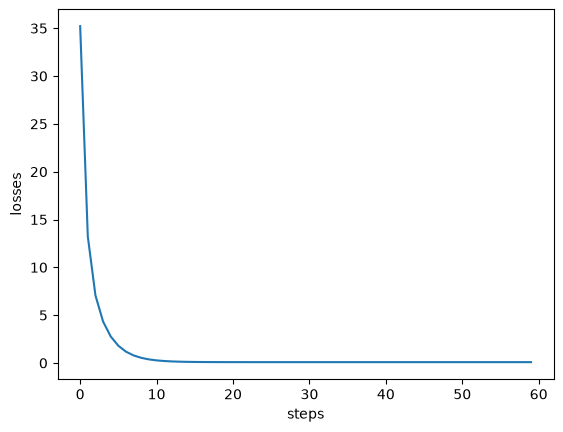

In [19]:
plt.plot(losses["step"], losses["loss"])
plt.xlabel("steps")
plt.ylabel("losses")

In [20]:
w = torch.scalar_tensor(0.0, requires_grad=True)
b = torch.scalar_tensor(0.0, requires_grad=True)

learning_rate = 1
steps = 100

losses = defaultdict(list)
for step in range(steps):
    w.grad = None
    b.grad = None

    y_pred = w * x + b
    loss = torch.mean((y_pred - y) ** 2)

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    losses["step"].append(step)
    losses["loss"].append(loss.item())
    if step % 2 == 0:
        print(f"Step: {step}, Loss: {loss}")

Step: 0, Loss: 35.21710205078125
Step: 2, Loss: 12812.279296875
Step: 4, Loss: 8525556.0
Step: 6, Loss: 5680158720.0
Step: 8, Loss: 3784417476608.0
Step: 10, Loss: 2521375851937792.0
Step: 12, Loss: 1.679871523189424e+18
Step: 14, Loss: 1.1192176205267688e+21
Step: 16, Loss: 7.456814546604398e+23
Step: 18, Loss: 4.968117327833537e+26
Step: 20, Loss: 3.31001811569233e+29
Step: 22, Loss: 2.2053060387498598e+32
Step: 24, Loss: 1.4692900371647516e+35
Step: 26, Loss: inf
Step: 28, Loss: inf
Step: 30, Loss: inf
Step: 32, Loss: inf
Step: 34, Loss: inf
Step: 36, Loss: inf
Step: 38, Loss: inf
Step: 40, Loss: inf
Step: 42, Loss: inf
Step: 44, Loss: inf
Step: 46, Loss: inf
Step: 48, Loss: inf
Step: 50, Loss: inf
Step: 52, Loss: inf
Step: 54, Loss: nan
Step: 56, Loss: nan
Step: 58, Loss: nan
Step: 60, Loss: nan
Step: 62, Loss: nan
Step: 64, Loss: nan
Step: 66, Loss: nan
Step: 68, Loss: nan
Step: 70, Loss: nan
Step: 72, Loss: nan
Step: 74, Loss: nan
Step: 76, Loss: nan
Step: 78, Loss: nan
Step: 80,

### Why does a learning rate of 1.0 cause the loss to explode?
Correct. The loss can grow dramatically until the parameters or calculations produce inf or nan.
For this dataset, the weight's gradient is strongly affected by the scale of \(x\). Since \(x\) ranges from \(-3\) to \(3\), the loss function can be relatively steep in the weight direction. A learning rate of 1.0 makes updates far too large.
Conceptually:
1. The gradient points toward a direction of decreasing loss locally.
2. A large learning rate takes an enormous step in that direction.
3. That step may cross far beyond the minimum.
4. The next gradient can become much larger, producing an even bigger update.
5. Eventually, floating-point values overflow, yielding inf or nan.

This is called **divergence**.\
A nuance worth remembering: a large learning rate doesn't guarantee divergence for every model or dataset. It is too large relative to the curvature and scaling of this particular optimization problem.